# NLP — 14. Attention

We're now entering one of the **most important concepts in NLP and Generative AI.**

We've studied RNN, LSTM, GRU, Seq2Seq, and Encoder–Decoder. Now we'll understand the problem that led to Attention and how Attention solves it.

## 1. Why do we need Attention?

Imagine translating this sentence from English to French:

> "The animal didn't cross the street because it was too tired."

When translating the word **"it"**, the model needs to understand which earlier word it refers to: "animal".
Now consider a longer sentence. The information needed to generate a particular output word might be located far back in the input.
A basic encoder–decoder model may compress the entire input into a single fixed-size representation. This can make long sequences difficult to handle.

The decoder has limited access to the details of the original input.

**Attention was introduced to help the decoder access the most relevant parts of the input when generating each output token.**

## 2. What is Attention?

**Attention is a mechanism that allows a model to assign different levels of importance to different parts of the input.**

Think about reading a question and searching a paragraph for the information needed to answer it.

You don't treat every word in the paragraph as equally important. You focus on the relevant words.

Attention works in a similar way.

Consider translating:

When generating `chats`, the model should focus strongly on `cats`.

When generating `J'aime`, it should focus more on `I love.`

Conceptually:

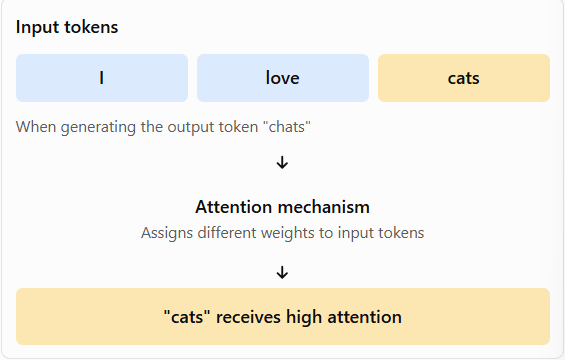

## 3. How does Attention work?

At a high level, the process has three steps.

**1. Calculate relevance:** Determine how relevant each input token is to the current task or output token.

**2. Calculate attention weights:** Convert the relevance scores into weights, commonly using the softmax function.

**3. Combine information:** Use the weights to create a representation that emphasizes the more relevant information.

For example, suppose the model needs to generate the word chats.

Imagine it calculates these attention weights:

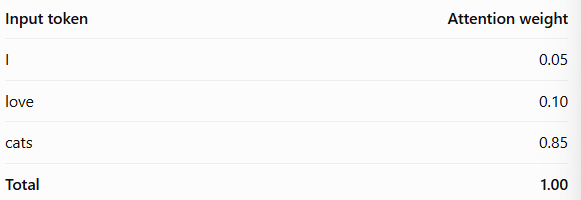

These are illustrative numbers. They show how the model could assign greater importance to `cats` for this output.


The weights are combined with representations of the input tokens to produce a **context vector.**

A higher attention weight means a token contributes more strongly to that particular attention calculation. It doesn't automatically mean the token is universally more important.

## 4. Attention versus the basic Encoder-Decoder

This is the central difference.

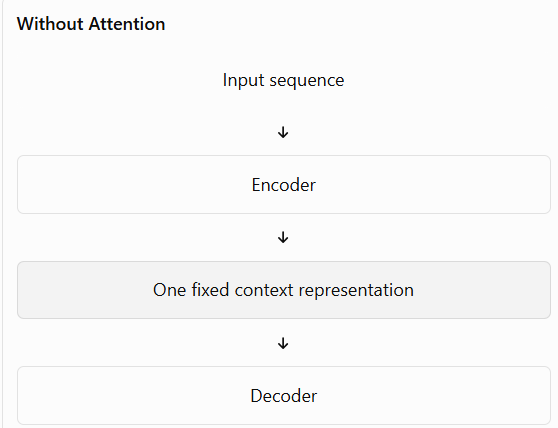

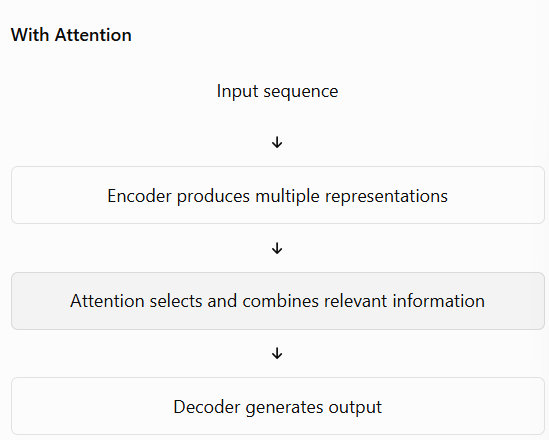

In classic attention-based Seq2Seq models, the decoder can use a different weighted combination of encoder states at each output step.

This reduces the information bottleneck of relying only on one fixed representation.

## 5. What are Query, Key, and Value?

You'll see these three terms repeatedly when learning Transformers.

They are the building blocks of the modern **scaled dot-product attention** mechanism.

A useful analogy is a search system:

- **Query (Q):** What information am I looking for?
- **Key (K):** What information does each available item correspond to?
- **Value (V):** What information does each item contain that I can retrieve?

Attention compares the query with the keys to calculate relevance scores, then uses those scores to combine the values.

For now, remember:

**Query searches, Key matches, Value provides the information.**

```
Q → [what we’re looking for]
K → [what we have]
V → [information to return]
```

We'll derive the actual equations in the next lessons.

## 6. Different types of Attention

There are several related concepts. They shouldn't be treated as identical.

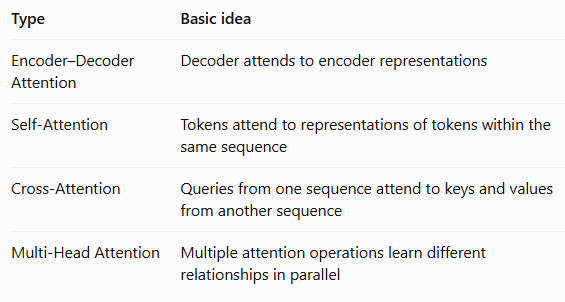

These concepts will become clearer when we study Query, Key, and Value.

One important distinction: **self-attention is not the same as cross-attention.** In self-attention, queries, keys, and values come from the same sequence representation; in cross-attention, queries come from one sequence and keys/values from another.

## 7. Why is Attention important for GenAI?

There are five major reasons 

### ① Understands relationships between words

Consider:

"The dog chased the cat because it was running."

To interpret **"it"**, the model needs to consider the surrounding words.

Attention helps the model learn relationships between tokens, including relationships between words that are far apart.

### ② Handles long sequences better

Without attention, a basic sequence-to-sequence model may struggle to preserve all the information in a long input.

Attention provides direct access to relevant encoder states, helping reduce this bottleneck.

### ③ Enables Transformers

This is the biggest connection to modern GenAI.

The Transformer architecture, introduced in the 2017 paper *Attention Is All You Need*, uses attention as a core mechanism rather than relying on recurrent processing.

### ④ Helps LLMs generate text

When you ask ChatGPT a question, the model processes tokens and uses attention to learn which other tokens are relevant to its next-token prediction.

For example:

**Prompt:** "Python is a programming language. It is widely used for ______."

The model can use the relationship between "Python," "programming language," and the surrounding context to predict a suitable continuation.

Attention helps the model use contextual information; it does not guarantee that the answer will be correct.

### ⑤ Supports many GenAI applications

Attention is important in systems that perform tasks such as:

- Text generation and summarization
- Machine translation
- Question answering
- Code generation
- Image generation using Transformer-based architectures
- Multimodal tasks involving text, images, and other data

In [ ]:
#Attention helps models process relationships between tokens and determine which information to use when building representations.
#It is a foundational component of the Transformer architecture, which underpins many modern language models.

## 8. What you should remember

- **Attention** assigns different weights to information based on relevance.
- It helps address the information bottleneck in early Seq2Seq architectures.
- Attention weights are used to combine input representations into a context-aware representation.
- **Query, Key, and Value** are central to scaled dot-product attention.
- **Self-attention** is a key building block of Transformers.

# NLP — 15. The Attention Mechanism: Query, Key, Value and Attention Scores.

In the previous lesson, we learned that Attention allows a model to focus on relevant parts of a sequence.

Now let's understand **how Attention calculates relevance mathematically.**

We'll cover the intuition, a numerical example, the formula, and a small Python implementation.

## 1. Understanding Query, Key, and Value

Imagine this sentence:

> "The cat sat on the mat because it was tired."

Suppose the model is processing the word **"it"** and needs to determine which earlier words are relevant.

Attention uses three vectors:

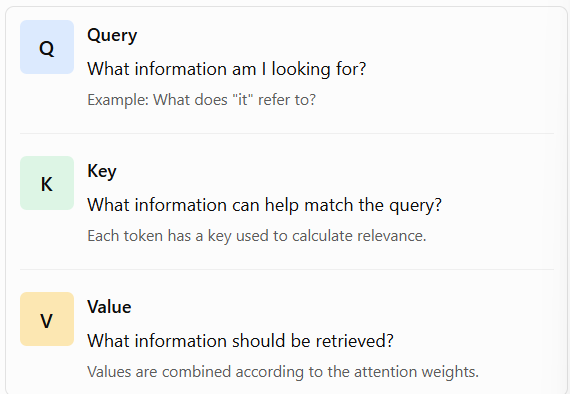

The key distinction is:

- **Query and Key** determine how strongly tokens relate.
- **Value** supplies the information that gets combined.

These are learned vector representations, not literal questions and labels.

## 2. How does Attention calculate relevance?

Suppose a query is compared with three keys.

For a simple example, imagine the similarity scores are:

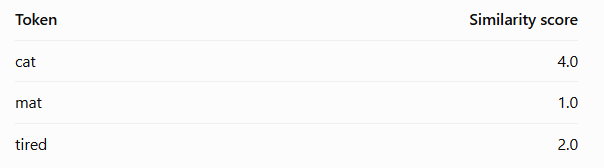

A higher score means the query matches that key more strongly in this example.

However, these scores aren't yet attention weights. We usually apply **softmax** to turn them into normalized weights.

Softmax converts scores into positive values that sum to 1.

For scores $s_1, s_2, \ldots, s_n$, the Softmax function calculates the attention weights:

$$
\alpha_i = \frac{e^{s_i}}{\displaystyle\sum_{j=1}^{n} e^{s_j}}
$$

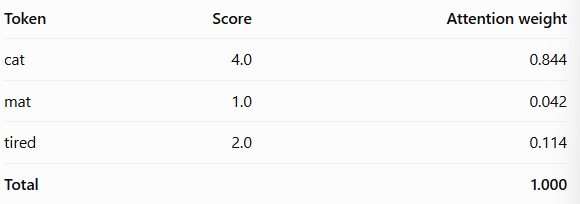

The model would give the `cat` value the largest contribution to the resulting representation.

*These numbers are illustrative, not actual scores from a trained model.*

## 3. The complete Attention formula

The standard **Scaled Dot-Product Attention** formula is:
$$
\boxed{\operatorname{Attention}(Q,K,V)=
\operatorname{softmax}\left(
\frac{QK^\top}{\sqrt{d_k}}
\right)V}
$$
Let's break it down.

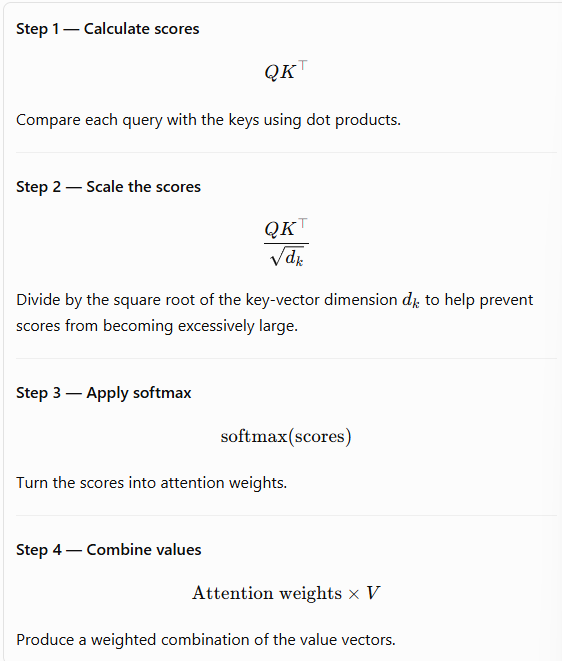

The final result is a new representation that incorporates information from the relevant tokens.

## 4. Why do we divide by $\sqrt{d_k}$?

### 1. What does $\sqrt{d_k}$ mean?

- Q = Query
- K = Key
- V = Value
- ${d_k}$ = Dimension of the key vectors
- $\sqrt{d_k}$ = Square root of the key dimension

### 2. Why do we divide by it?

**The main reason is to prevent attention scores from becoming too large.**

When the key and query vectors have many dimensions, their dot products can become large in magnitude.

Large scores can cause the Softmax function to produce extremely peaked probabilities, making its gradients very small and learning more difficult.

Dividing by $\sqrt{d_k}$ helps keep the scores at a suitable scale.

### 3. Simple numerical example

Suppose the dot product produces these attention scores:

$$
QK^T = [20,\ 10,\ 5]
$$

Assume the key dimension is $d_k = 16$.

Therefore,

$$
\sqrt{d_k} = \sqrt{16} = 4
$$

**Without Scaling:**

$$
\operatorname{Softmax}([20,\ 10,\ 5])
\approx [0.99995,\ 0.000045,\ 0.0000003]
$$

The first score dominates almost completely.

**With Scaling:**

Divide each score by $\sqrt{d_k} = 4$:

$$
\frac{[20,\ 10,\ 5]}{4}
=
[5,\ 2.5,\ 1.25]
$$

Now apply the Softmax function:

$$
\operatorname{Softmax}([5,\ 2.5,\ 1.25])
\approx [0.905,\ 0.074,\ 0.021]
$$

The scores are now less extreme, allowing other positions to receive more meaningful attention weights.

*Note: These values are illustrative.*

### 4. Remember This

| Without Scaling | With Scaling |
|---|---|
| Scores may become too large. | Scores are kept at a more suitable scale. |
| Softmax can produce extremely peaked probabilities. | Softmax is less likely to produce excessively peaked probabilities. |
| Gradients can become very small. | Helps maintain more useful gradients. |

**One-line takeaway:**

We divide the dot-product scores by $\sqrt{d_k}$ to prevent them from becoming too large, helping Softmax avoid extremely small gradients and supporting stable, effective training.

## 5. A small Python implementation

Let's implement the formula using NumPy. We'll use tiny, invented vectors to understand the mechanics.

In [2]:
# Import NumPy
import numpy as np

# Define Query(Q), Key(K), Value(V)
# For this example , we'll use three 2-dimensional vectors
# One query and three keys, each with 2 dimensions

Q = np.array([1, 0])

K = np.array([
    [1, 0],    # Key 1
    [0, 1],    # Key 2
    [1, 1]     # Key 3
])

# Each key has a corresponding value vector
V = np.array([
    [10, 0],
    [0, 10],
    [5, 5]
])

In [5]:
# Calculate the similarity scores

scores = Q @ K.T #The @ operator performs matrix multiplication. The query matches Keys 1 and 3 equally in this example.
print(scores)

[1 0 1]


In [7]:
# Scale the scores
d_k = K.shape[1]
scaled_scores = scores / np.sqrt(d_k)

print("Scaled_scores:",scaled_scores)

Scaled_scores: [0.70710678 0.         0.70710678]


In [8]:
# Apply softmax
# Softmax converts the scaled scores into attention weights that sum to 1.

def softmax(x):
    exp_x = np.exp(x - np.max(x))
    return exp_x / np.sum(exp_x)

attention_weights = softmax(scaled_scores)

print("Attention weights:", attention_weights)
print("Sum of weights:", attention_weights.sum())
#The first and third keys receive more attention than the second key.

Attention weights: [0.40111209 0.19777581 0.40111209]
Sum of weights: 1.0


In [10]:
# Calculate the attention output

attention_output = attention_weights @ V

print("Attention output:", attention_output)
#The output is a weighted combination of the three value vectors.

Attention output: [6.01668139 3.98331861]


In [11]:
# Why? The output combines the value vectors using the attention weights. Keys 1 and 3 receive more weight than Key 2.
#Important: This example demonstrates the mathematics. Real models learn their Q, K, and V projections from training data.

## 6. What happens inside a Transformer?

In a Transformer, input token representations are transformed using learned weight matrices:

$$
Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V
$$

Here:
- $X$ = input token representations
- $W_Q$ = learned query projection
- $W_K$ = learned key projection
- $W_V$ = learned value projection

These projections allow the model to learn how to compare tokens and what information to pass between them.

The attention operation then combines the projected vectors according to the formula we just studied.

## Remember this formula

$$
\boxed{\operatorname{Attention}(Q,K,V)=
\operatorname{softmax}\left(
\frac{QK^\top}{\sqrt{d_k}}
\right)V}
$$

The next important concept is **Self-Attention.**

In self-attention, tokens within the same sequence can attend to one another. This allows the model to build context-aware representations without relying on a recurrent hidden state passing through the sequence one step at a time.

That is the next step toward understanding how Transformers work

# NLP — 16. Self-Attention

We've learned the Attention formula and the roles of Query, Key, and Value. Now let's understand **Self-Attention**, one of the core building blocks of Transformers.

## 1. What is Self-Attention?

**Self-Attention allows each token in a sequence to use information from other tokens in that same sequence to build a context-aware representation.**

Consider:

> The animal didn't cross the street because it was tired.

To understand `it`, a model may need information from `animal`.

Self-attention allows tokens to calculate how relevant other tokens are to their own representations.

The model can learn relationships between tokens even when they are far apart in the sentence.

## 2. How is it different from ordinary Attention?

In the encoder-decoder attention we discussed earlier, the decoder can attend to the encoder's input representations.

In **self-attention**, the queries, keys, and values are all derived from the same sequence.

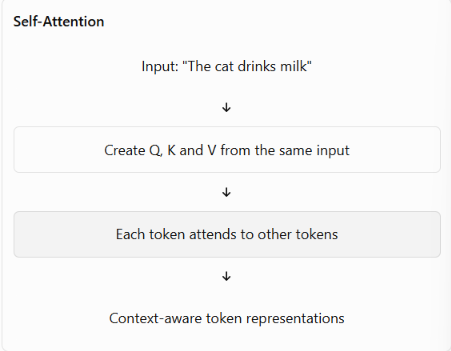

For example, the representation of drinks can incorporate information from `cat` and `milk`, helping the model represent their relationship.

## 3. How does it work?

Let's use the sentence:
`The cat drinks milk`

Self-attention follows four main steps.

**1. Create Query, Key, and Value vectors.** Each token representation is projected into three vectors using learned weights.

**2. Calculate attention scores**. Compare each query with the keys of the tokens in the sequence.

**3. Apply softmax.** Convert the scores into attention weights.

**4. Combine the values**. Use the weights to produce a new representation for each token.

For example, the query for `cat` could assign different weights to `The`, `drinks`, and `milk.`

The exact weights are learned through the model's training; they aren't manually assigned.

## 4. A small numerical example

Suppose a token's attention weights over three tokens are:

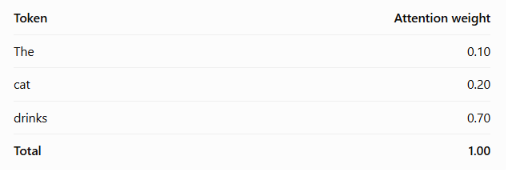

The new representation is a weighted combination:

$$
z = 0.10v_{\text{The}}+0.20v_{\text{cat}}+0.70v_{\text{drinks}}
$$

Here, $v\$ represents each token's value vector.

The `drinks` value contributes most strongly to this particular output. These are illustrative weights, not results from a trained model.

**Important:** Each token gets its own attention calculation and resulting representation. Self-attention doesn't produce just one vector for the whole sentence.

## 5. The formula

The scaled dot-product attention formula we learned earlier also applies to self-attention:
$$
\operatorname{Attention}(Q,K,V)
=\operatorname{softmax}\left(
\frac{QK^\top}{\sqrt{d_k}}
\right)V
$$

The difference is the source of the vectors:
$$
Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V
$$

- $X$: representations of the input tokens
- $W_Q,W_K,W_V$: learned projection matrices
- $d_k$: key-vector dimension

Because all three projections originate from $X\$, this is self-attention.

## 6. Why is Self-Attention so useful?

- **Long-range relationships:** Tokens can connect directly to other tokens instead of passing information only through a recurrent chain.
- **Contextual representations:** The representation of a token can change depending on the surrounding sequence.
- **Parallel processing:** The attention calculations for multiple tokens can be performed in parallel during training, subject to the model's masking rules.
- **Foundation for Transformers:** Self-attention is a central component of the Transformer architecture. 

One limitation is that basic self-attention does not automatically understand word order. Transformers need positional information, which we'll cover later.

## 7. One important distinction: causal vs. bidirectional

Self-attention does not always allow every token to look at every other token.

- **Bidirectional self-attention:** A token can attend to tokens on both its left and right, subject to any padding mask.
- **Causal self-attention:** A token can attend only to itself and earlier tokens, not future tokens.

This distinction is important for understanding BERT-style and GPT-style models.

We'll study it separately next.

**Next: NLP — 17. Causal vs. Bidirectional Attention.** We'll compare how BERT-style and GPT-style models use attention differently.

# NLP — 17. Causal vs. Bidirectional Attention

In the previous lesson, we learned that Self-Attention allows tokens to gather information from other tokens. But should a token be allowed to look at **future tokens**, or only at the tokens that came before it?

The answer depends on the model's purpose.

### 1. Bidirectional Self-Attention

Bidirectional attention allows a token to attend to tokens on **both sides** of its position.

Consider:

`The cat drinks milk`

When processing `drinks`, the model can use information from both earlier and later tokens.

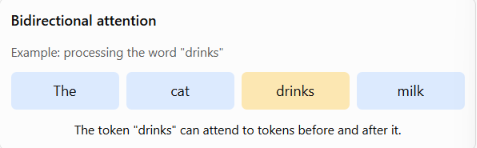

This helps a model understand a word using its full sentence context.

**Example model: BERT** — a Transformer encoder model commonly used for language understanding tasks.

### 2. Causel Self-Attention

Causal attention restricts a token from attending to **future tokens**. It can attend to itself and earlier tokens.

Consider the same sentence:

`The cat drinks milk`

When generating `drinks`, the model can use `The` and `cat`, but it cannot use `milk`, because that token comes later.

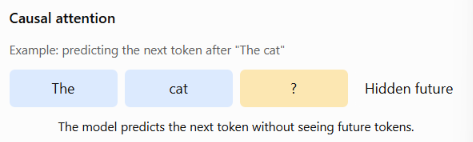

**Example model family: GPT-style decoder-only Transformers.** Causal attention allows them to generate text one token at a time without accessing the answer in advance.

### 3. The key difference

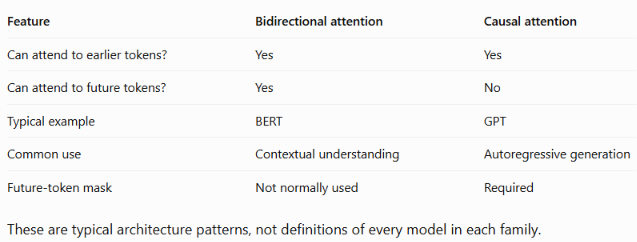

### 4. How does the model block future tokens?

It uses an **attention mask.**

For a sequence of four tokens, a causal mask can be represented as:

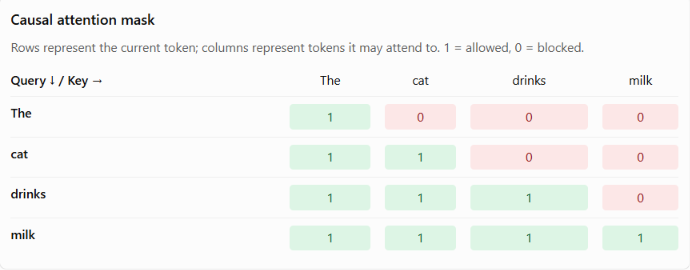

For example, the row for `cat` permits attention to `The` and `cat`, but blocks `drinks` and `milk`.

In actual Transformer implementations, blocked positions are usually assigned a very negative score before softmax, making their attention weights effectively zero.

We'll explore attention masks properly in the next lesson.

### 5. Why not always use bidirectional attention?

Because the task matters.

For example, suppose we are training a model to predict the next word:

`The cat drinks ___`

If the model could look at the actual future word `milk` while predicting it, that would leak the answer.

Causal masking prevents this during training. The model learns to predict the next token using only the preceding context.

By contrast, when BERT learns contextual representations of text, it can use both left and right context.

### Remember this

- **Bidirectional:** looks left and right; useful for understanding the full context.
- **Causal:** looks left and at itself; essential for standard autoregressive next-token generation.
- **Attention masks:** control which token positions are allowed to interact.

**Next → NLP — 18. Attention Masks**
We'll cover padding masks, causal masks, and how masks affect the attention calculation, with a small Python example.

# NLP — 18. Attention Masks

In the previous lesson, we learned that causal attention prevents a token from looking at future tokens. Now let's understand how **attention masks control which tokens a model is allowed to attend to.**

## 1. What is an attention mask?

An attention mask tells the model which token positions should be considered and which should be ignored during an attention calculation.

There are two important cases:

**1. Padding mask** — prevents the model from attending to padding tokens.

**2. Causal mask** — prevents the model from attending to future tokens.

They solve different problems.

## 2. Padding mask

Consider these two sentences:

Batches of sentences are often padded so they have the same length.

For example:

`[PAD]` is a special token added to make the sequences the same length.

It isn't meaningful content from the original sentence. A padding mask prevents attention from treating that padding position as useful information.

The mask might look like this:

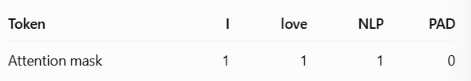

Here, `1` indicates a real token and 0 indicates padding. This is a common convention for tokenizer attention masks, though internal implementations may use different conventions.

**Important:** A padding mask and a causal mask are not interchangeable.

## 3. Causal mask

Causal masking is used in autoregressive language models, such as GPT-style models, to prevent access to future tokens.

Consider:

The model should be able to use previous tokens to predict the next one, but it must not see future tokens while making that prediction.

A causal mask can look like this:

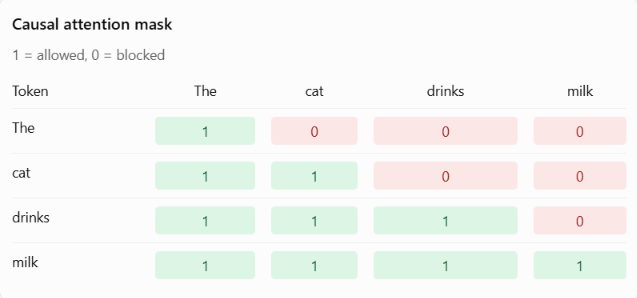

The first token can attend only to itself. The second can attend to the first and second tokens, and so on.

This prevents the model from using future-token information when predicting the next token.

## 4. How are masks applied mathematically?

Recall our attention formula:

$$
\operatorname{Attention}(Q,K,V)
=\operatorname{softmax}\left(
\frac{QK^\top}{\sqrt{d_k}}
\right)V
$$

A mask is applied to the scores **before softmax.**

Conceptually, blocked positions receive a very large negative value:
$$
S_{\text{masked}}=
\begin{cases}
S_{ij}, & \text{if attention is allowed}\\
-\infty, & \text{if attention is blocked}
\end{cases}
$$

Then:
$$
A=\operatorname{softmax}(S_{\text{masked}})
$$

Because the softmax of a negative infinity score is zero, blocked positions receive zero attention weight.

## 5. Python example: causal mask

In [3]:
# Let's create a simple causal mask using NumPy.

In [8]:
import numpy as np

sequence_length = 4

# 1 = allowed, 0 = blocked
causal_mask = np.tril(
    np.ones((sequence_length, sequence_length))
)

print(causal_mask)

[[1. 0. 0. 0.]
 [1. 1. 0. 0.]
 [1. 1. 1. 0.]
 [1. 1. 1. 1.]]


In [6]:
#Now apply it to example attention scores:

In [9]:
scores = np.array([
    [2.0, 1.0, 3.0, 4.0],
    [1.0, 3.0, 2.0, 4.0],
    [2.0, 1.0, 3.0, 4.0],
    [1.0, 2.0, 3.0, 4.0]
])

masked_scores = np.where(
    causal_mask == 1,
    scores,
    -np.inf
)

print(masked_scores)

[[  2. -inf -inf -inf]
 [  1.   3. -inf -inf]
 [  2.   1.   3. -inf]
 [  1.   2.   3.   4.]]


In [16]:
# After softmax, its attention weights are:

[1.0, 0.0, 0.0, 0.0] #for 1st row

# The first token cannot access the future tokens.

[1.0, 0.0, 0.0, 0.0]

## 6. Padding mask vs. causal mask

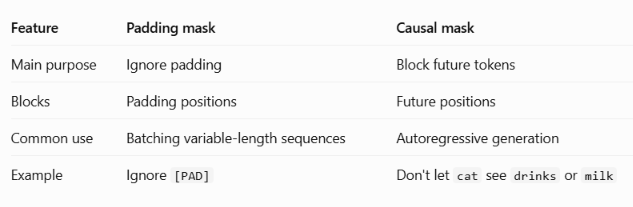

Both masks can be used together when a model needs both protections.

## What to remember

- **Padding mask:** prevents padding tokens from contributing as meaningful content.

- **Causal mask:** prevents tokens from accessing future positions.

- Masks are applied to attention scores before softmax.

- Masking is essential to ensure the model follows the intended information-flow rules.

**Next → NLP — 19. Multi-Head Attention**

We'll learn why Transformers use multiple attention heads instead of relying on just one, and how those heads work together.

# NLP — 19. Multi-Head Attention

So far, we've learned how attention calculates relevance using Query, Key, and Value. Now the question is:

Why does a Transformer use multiple attention heads instead of just one?

## 1. The idea behind Multi-Head Attention

Imagine the sentence:
> "The student opened the book because she needed to study."

Different relationships matter in this sentence:

- `she` relates to `student`.
- `opened` relates to `book`.
- `study` relates to `needed`.

A single attention head calculates one set of attention relationships for its learned Q, K, and V projections.

**Multi-Head Attention uses multiple attention heads in parallel**, allowing the model to learn different types of relationships simultaneously.

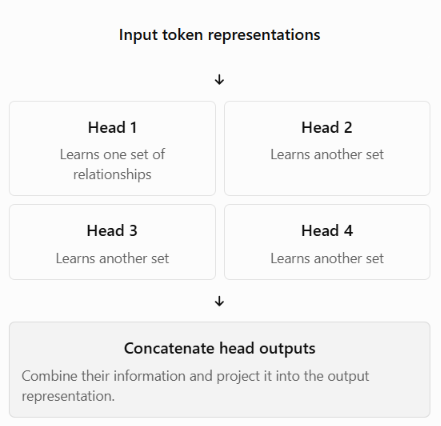

The examples of relationships above are intuitive illustrations. The model learns its own attention patterns; each head isn't manually assigned a grammatical job.

## 2. How does one attention head work?

One head performs the calculation we've already studied:
$$
\operatorname{head}_i =
\operatorname{softmax}
\left(\frac{Q_iK_i^\top}{\sqrt{d_k}}\right)V_i
$$

Each head has its own learned query, key, and value projections.

Multi-Head Attention runs several versions of this process in parallel, using different learned projections.

## 3. How are multiple heads combined?

Suppose there are four heads.

The outputs are concatenated along their feature dimension and passed through a learned output projection.

The standard formula is:
$$
\operatorname{MHA}(Q,K,V)
=\operatorname{Concat}(h_1,\ldots,h_h)W_O
$$

Here:
- $h_i$ = output of attention head \(i\)
- $h$ = number of heads
- $W_O$ = learned output projection matrix

This allows the model to combine information from the different heads.

## 4. Why not just use one big attention head?

Multiple heads provide different learned projections of the input. This lets the model represent different relationships in parallel instead of relying on one attention calculation.

For example, when processing:

`The dog chased the ball because it was moving.`

different heads might learn patterns involving:

- relationships between entities and pronouns
- nearby word relationships
- longer-range dependencies

These are possible learned patterns, not guaranteed roles for individual heads.

## 5. A simple numerical example

Suppose a model uses two heads and produces these illustrative outputs for a token:

In [2]:
import numpy as np

head_1 = np.array([0.2, 0.8])
head_2 = np.array([0.7, 0.3])

# Combine the outputs from both heads
combined = np.concatenate([head_1, head_2])

print(combined)

[0.2 0.8 0.7 0.3]


In [3]:
# This is the concatenation step only. A real Transformer then applies a learned output projection:

In [4]:
W_o = np.array([
    [1.0, 0.0],
    [0.0, 1.0],
    [0.5, 0.5],
    [0.5, -0.5]
])

output = combined @ W_o
print(output)

[0.7 1. ]


This gives a two-dimensional output representation. In a real model, the projection matrix is learned during training; our numbers are only for demonstration.

## 6. Does more heads always mean a better model?

No. More heads increase the model's capacity to learn different relationships, but they also affect computation and parameterization. Some heads may learn overlapping or less useful patterns.

The number of heads is a design choice, not a guarantee of better performance.

## 7. What you should remember

- **Single-head attention:** one learned attention operation.

- **Multi-Head Attention:** multiple attention operations in parallel.

- Each head has its own learned Q, K, and V projections.

- Head outputs are concatenated and passed through an output projection.

- Multiple heads help the model learn different relationships between tokens.

**Next: NLP — 20. Positional Information**

Self-attention by itself doesn't inherently encode token order. Next we'll learn how Transformers distinguish "dog bites man" from "man bites dog" and how positional information is added to token representations.

## NLP — 20. Positional Information